## Importing Libaries and Data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from helpers import *
from implementations import *

# []


## Loading code and preprocessing

In [2]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("dataset")

# can use python to read the column names and assign them to each array to use the same structure as pandas later

with open("dataset/x_train.csv") as f:
    header = f.readline().strip().split(",")

feature_names = np.array(header[1:])
print(len(feature_names), x_train.shape[1])

col = {name: i for i, name in enumerate(feature_names)}

321 321


In [3]:
y_train[y_train == -1] = 0  # submission require 1 or -1 in the end so is fine as long as we remember to change it back

# i dont think we are allowed to use pandas but i reckon it should be fine just as arrays

In [4]:
# can just use y train straight since we are doing pandas tables any more

N = y_train.shape[0]
total_disease = (y_train == 1).sum()

print(f"Percentage of Patients with MICHD in the training set: {(total_disease/N)*100: .2f} %")

Percentage of Patients with MICHD in the training set:  8.83 %


In [5]:
# creating a preprocessing function that 'fits' the training data and then 'cleans' it

def fit_preprocessing(x):
    """Learn the preprocessing numbers and store them as paramters.

    Drops columns with 60% or more missing values, then computes the
    median (for filling NaNs) and the mean and standard deviation
    (for standardizing) of each remaining column.

    Args:
        x = numpy array of shape (N, D_raw). Raw training features, may contain NaNs

    Returns:
        params = dict with
            "keep" = boolean array, shape (D_raw, ), True for columns kept
            "median" = float array of shape (D_kept,), median of each kept column.
            "mean" = float array of shape (D_kept,), mean of each kept column after filling NaNs.
            "std" = float array of shape (D_kept,), standard deviation of each kept column after filling NaNs (0 replaced by 1).
    """

    fraction_missing = np.isnan(x).mean(axis=0)
    keep = fraction_missing < 0.6 # we drop any columns with more than 60% missing values

    x = x[:, keep]
    median = np.nanmedian(x, axis=0)
    x = np.where(np.isnan(x), median, x)

    mean = x.mean(axis=0)
    std = x.std(axis=0)
    std[std == 0] = 1

    params = {"keep": keep, "median": median, "mean": mean, "std": std}

    return params

def clean_preprocessing(x, params):
    """Clean the data using the parameters found above.

    Keeps the selected columns, fills NaNs with the training medians,
    standardizes with the training mean and std, and adds a bias column.

    Args:
        x = numpy array of shape (N, D_raw). Raw features (training, validation or test), may contain NaNs.
        params = returned by fit_preprocessing.

    Returns:
        tx = numpy array of shape (N, D_kept + 1). Cleaned feature matrix, with a column of ones as the first column.
    """

    x = x[:, params["keep"]]
    x = np.where(np.isnan(x), params["median"], x)
    x = (x - params["mean"]) / params["std"]

    tx = np.c_[np.ones(x.shape[0]), x]

    return tx

# When you add new steps later, like code cleaning or one-hot encoding, 
# update both docstrings and the list of keys in params at the same time, so they never fall out of sync.

## Exploring regularized logisitc regression

In [6]:
# Splitting the training data into a training and a validation set for hyperparameter tuning
# calling it validation instead of test so we dont get confused with the actual test dataset instead of our internal splitting here

def split_data(x, y, ratio, seed=1):
    """
    Args:
        x: numpy array of shape (N, D), N is the number of samples.
        y: numpy array of shape (N,).
        ratio: scalar in [0,1]
        seed: integer.

    Returns:
        x_tr: numpy array containing the train data.
        x_va: numpy array containing the validation data.
        y_tr: numpy array containing the train labels.
        y_va: numpy array containing the validation labels.
    """
    # set seed
    np.random.seed(seed)
    N = x.shape[0]

    shuffled_indices = np.random.permutation(N)
    cutoff = int(np.floor(ratio * N))

    train_indices = shuffled_indices[:cutoff]
    val_indices = shuffled_indices[cutoff:]

    x_tr, x_va = x[train_indices], x[val_indices]
    y_tr, y_va = y[train_indices], y[val_indices]

    return x_tr, x_va, y_tr, y_va


In [7]:
x_tr, x_va, y_tr, y_va = split_data(x_train, y_train, 0.8, seed=1)

params = fit_preprocessing(x_tr)
tx_tr = clean_preprocessing(x_tr, params)
tx_va = clean_preprocessing(x_va, params)

In [8]:
# initial values
initial_w = np.zeros(tx_tr.shape[1])
max_iters = 30
lambda_ = 0
gammas = [1, 1.5, 2, 2.5, 3]

min_loss = np.inf
best_gamma = None

# reg logistic regression to find best step size
for gamma in gammas:
    w, loss = reg_logistic_regression(y_tr, tx_tr, lambda_, initial_w, max_iters, gamma)
    if min_loss > loss:
        min_loss = loss
        best_gamma = gamma
    print(f"gamma = {gamma:<8} loss = {loss:.4f}")

print(f"Smallest Loss = {min_loss: .2f} Best gamma = {best_gamma}")

gamma = 1        loss = 0.2341
gamma = 1.5      loss = 0.2310
gamma = 2        loss = 0.2353
gamma = 2.5      loss = 0.2598
gamma = 3        loss = 0.3008
Smallest Loss =  0.23 Best gamma = 1.5


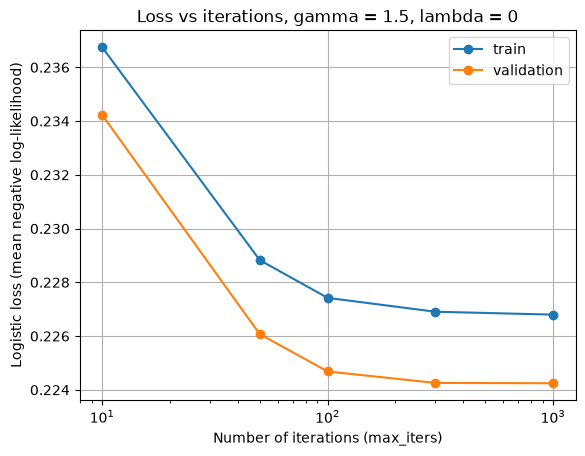

In [11]:
initial_w = np.zeros(tx_tr.shape[1])
gamma = 1.5
iters_list = [10, 50, 100, 300, 1000]
lambda_ = 0

losses_tr = []
losses_va = []

for max_iters in iters_list:
    w, loss_tr = reg_logistic_regression(y_tr, tx_tr, lambda_, initial_w, max_iters, gamma)
    loss_va = logistic_loss(y_va, tx_va, w)

    losses_tr.append(loss_tr)
    losses_va.append(loss_va)

# visualising loss against iterations

plt.plot(iters_list, losses_tr, marker="o", label="train")
plt.plot(iters_list, losses_va, marker="o", label="validation")
plt.xscale("log")
plt.xlabel("Number of iterations (max_iters)")
plt.ylabel("Logistic loss (mean negative log-likelihood)")
plt.title(f"Loss vs iterations, gamma = {gamma}, lambda = {lambda_}")
plt.legend()
plt.grid()
plt.show()


- both losses flatten around 10^2 iterations 
- both curves are pretty close together meaning that there isn't much overfitting at lambda = 0, but they get slightly further apart as iterations increase then flatten again
- the validation loss is lower than training loss which is a good sign

In [10]:
print(y_tr.mean())
print(y_va.mean())

0.08880491261218705
0.08629070352141649


## Results/thoughts

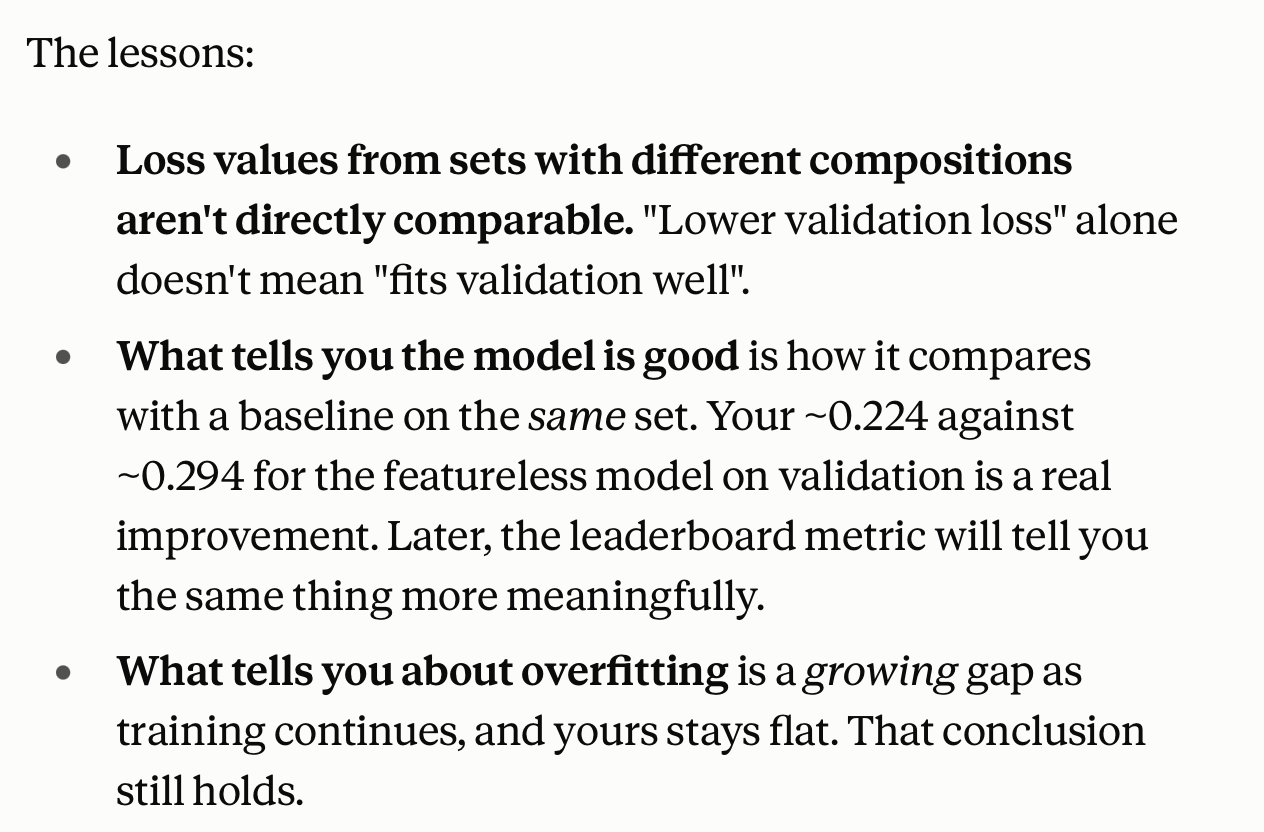

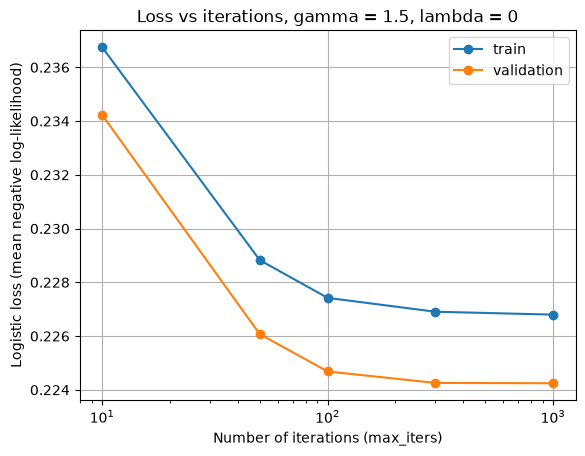